# **Outlier Handling**

>## **Outlier removal using Z-score.**

### **When Data Distribution is Normal**

In [250]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [251]:
data = pd.read_csv(r"C:\Users\LENOVO\Downloads\titanic.csv",usecols=['Age','Fare'])

In [252]:
data.dropna(inplace=True)

<Axes: ylabel='Density'>

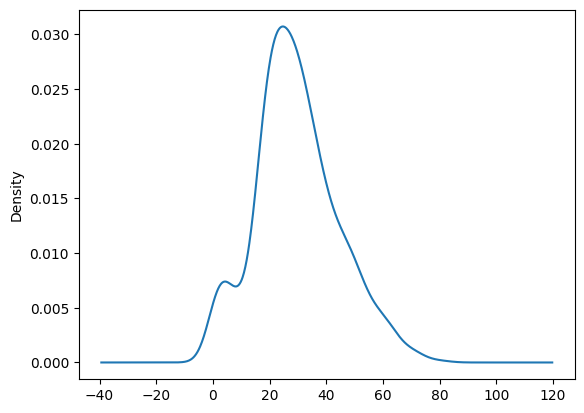

In [253]:
data['Age'].plot(kind='kde')

In [254]:
data.shape

(714, 2)

<Axes: >

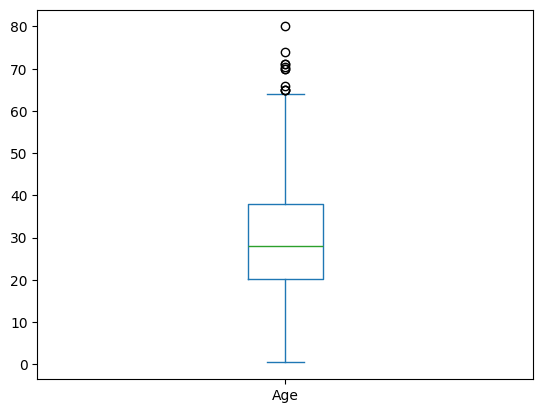

In [255]:
data['Age'].plot(kind='box')

In [256]:
mean = data['Age'].mean()
std = data['Age'].std()

In [257]:
print(f"Mean: {mean:.2f}, Standard Deviation: {std:.2f}")

Mean: 29.70, Standard Deviation: 14.53


In [258]:
# finding the boundaries for outliers using 3 standard deviations from the mean
lower_bound = mean - 3*std
upper_bound = mean + 3*std

In [259]:
# finding the outliers using z-score method
data[(data['Age']>upper_bound)]

,Age,Fare
630,80.0,30.000
851,74.0,7.775


## **Trimming**

In [260]:
# Trimming the outliers from the dataset
data_trim = data[(data['Age'] >= lower_bound) & (data['Age'] <= upper_bound)]

In [261]:
data_trim.head()

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500


In [262]:
data_trim.shape

(712, 2)

In [263]:
# approach 2 using Z-score method
data['Age_zscore'] = (data['Age'] - mean)/std

In [264]:
data.head()

,Age,Fare,Age_zscore
0,22.0,7.2500,-0.530005
1,38.0,71.2833,0.571430
2,26.0,7.9250,-0.254646
3,35.0,53.1000,0.364911
4,35.0,8.0500,0.364911


In [265]:
data[(data['Age_zscore'] > 3) | (data['Age_zscore'] < -3)]

,Age,Fare,Age_zscore
630,80.0,30.000,3.462699
851,74.0,7.775,3.049660


## **Capping**

In [266]:
data_cap = data.copy()

In [267]:
f_mean = data_cap['Age'].mean()
f_std = data_cap["Age"].std()

In [268]:
upp_limit = f_mean + 3 * f_std
low_limit = f_mean - 3 * f_std

In [269]:
data_cap['Age'] = np.where(data['Age']>upp_limit,
                        upp_limit, 
                       np.where(data['Age']<low_limit, 
                                low_limit, 
                                data['Age']))

In [307]:
data['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [270]:
data_cap['Age'].describe()

count    714.000000
mean      29.688694
std       14.492933
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       73.278610
Name: Age, dtype: float64

Text(0.5, 1.0, 'After capping')

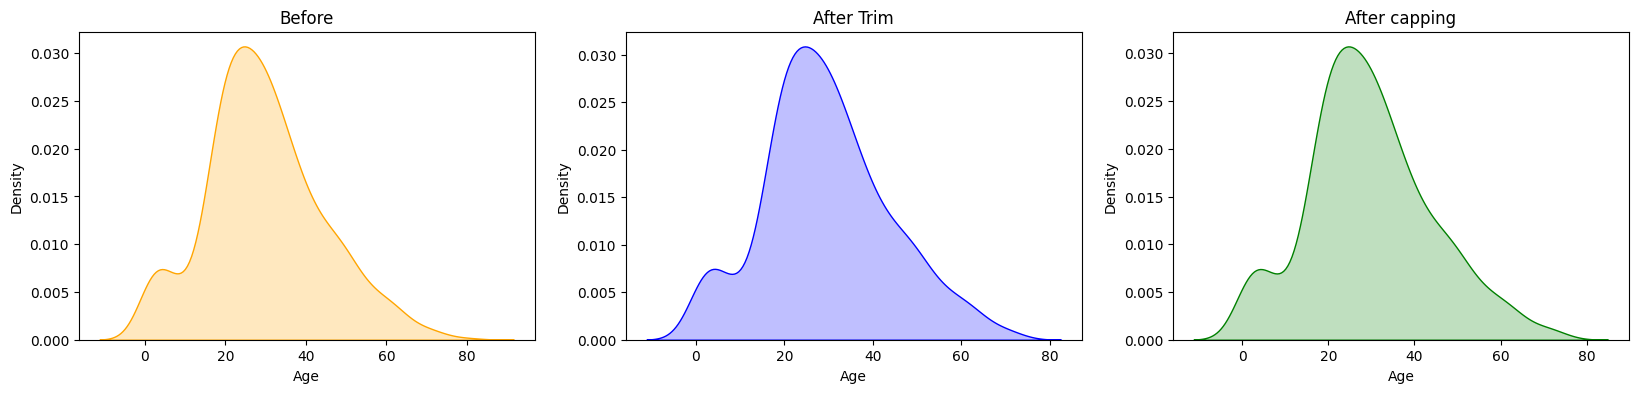

In [271]:
fig , (ax1,ax2,ax3) = plt.subplots(ncols=3,figsize=(20,4))
fig = sns.kdeplot(data['Age'],fill=True,color='orange',ax=ax1)
ax1.set_title('Before')
fig = sns.kdeplot(data_trim['Age'],fill=True,color='blue',ax=ax2)
ax2.set_title('After Trim')
fig = sns.kdeplot(data_cap["Age"],fill=True,color='green',ax=ax3)
ax3.set_title('After capping')

Text(0.5, 1.0, 'After capping')

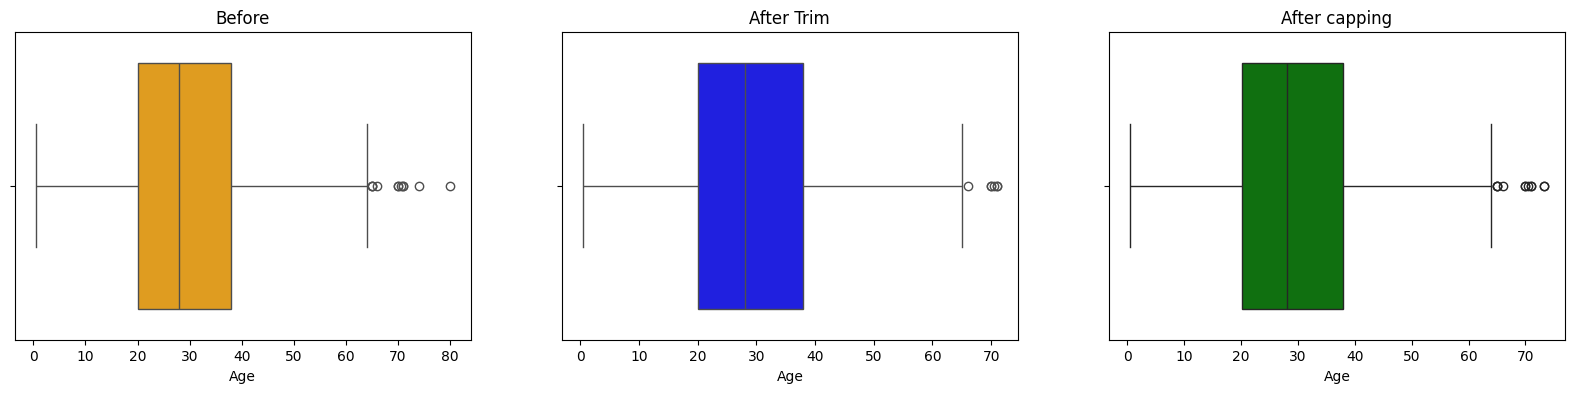

In [306]:
fig , (ax1,ax2,ax3) = plt.subplots(ncols=3,figsize=(20,4))
fig = sns.boxplot(x=data['Age'],color='orange',ax=ax1)
ax1.set_title('Before')
fig = sns.boxplot(x=data_trim['Age'],color='blue',ax=ax2)
ax2.set_title('After Trim')
fig = sns.boxplot(x=data_cap['Age'],color='green',ax=ax3)
ax3.set_title('After capping')

### **2 When Data distribution is skew**

In [272]:
data = pd.read_csv(r"C:\Users\LENOVO\Downloads\titanic.csv")

In [273]:
data.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [274]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


<Axes: ylabel='Density'>

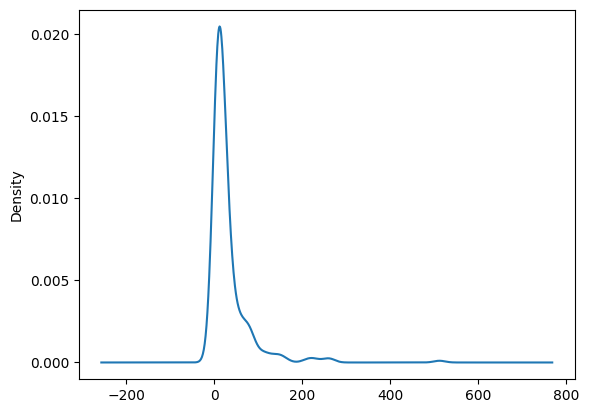

In [275]:
data['Fare'].plot(kind='kde')

In [276]:
data['Fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

<Axes: >

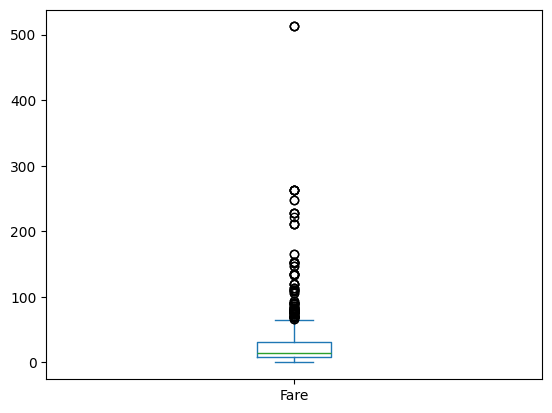

In [277]:
data['Fare'].plot(kind='box')

In [278]:
# Finding IQR
Q1 = data['Fare'].quantile(0.25) # 25 percentile
Q3 = data['Fare'].quantile(0.75)  # 75 percentile

In [279]:
IQR = Q3 - Q1
IQR

np.float64(23.0896)

In [280]:
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR

In [281]:
print('upper_limit:',upper_bound)
print('lower_limit:',lower_bound)

upper_limit: 73.27860964406094
lower_limit: -13.880374349943303


## **Finding Outliers**

In [282]:
data[data['Fare'] > upp_limit]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S
31,32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",female,NaN,1,0,PC 17569,146.5208,B78,C
34,35,0,1,"Meyer, Mr. Edgar Joseph",male,28.0,1,0,PC 17604,82.1708,NaN,C
52,53,1,1,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",female,49.0,1,0,PC 17572,76.7292,D33,C
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0000,B28,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0000,B28,NaN
835,836,1,1,"Compton, Miss. Sara Rebecca",female,39.0,1,1,PC 17756,83.1583,E49,C
849,850,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,NaN,1,0,17453,89.1042,C92,C
856,857,1,1,"Wick, Mrs. George Dennick (Mary Hitchcock)",female,45.0,1,1,36928,164.8667,NaN,S


In [283]:
data[data['Fare'] < lower_limit]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


### **Trimming**

In [284]:
new_data = data[data['Fare'] < upper_bound]

In [285]:
print('Before Trim: ',data.shape)
print('After Trim: ',new_data.shape)

Before Trim:  (891, 12)
After Trim:  (789, 12)


In [286]:
import matplotlib.pyplot as plt
import seaborn as sns

Text(0.5, 1.0, 'After Trim')

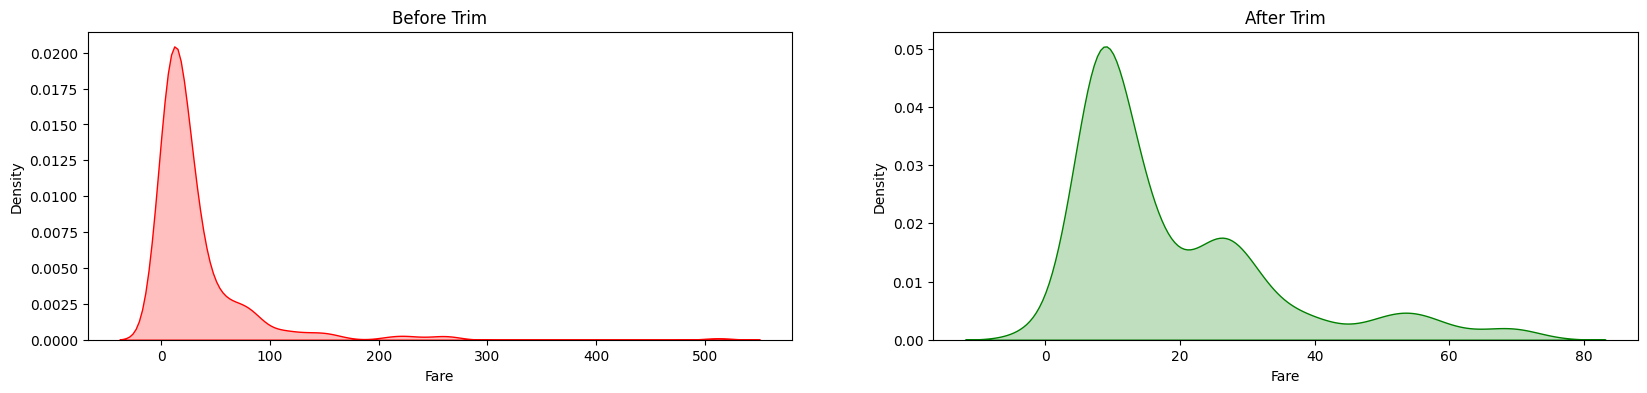

In [287]:
# comaparing
fig , (ax1,ax2) = plt.subplots(ncols=2,figsize=(20,4))
fig = sns.kdeplot(data['Fare'],fill=True,color='red',ax=ax1)
ax1.set_title('Before Trim')
fig = sns.kdeplot(new_data['Fare'],fill=True,color='green',ax=ax2)
ax2.set_title('After Trim')

## **Capping**

In [288]:
new_df_cap = data.copy()
new_df_cap['Fare'] = np.where(new_df_cap['Fare']>upper_limit,upper_limit
                              ,np.where(new_df_cap['Fare'] < lower_limit,lower_limit,new_df_cap['Fare']))

Text(0.5, 1.0, 'After capping')

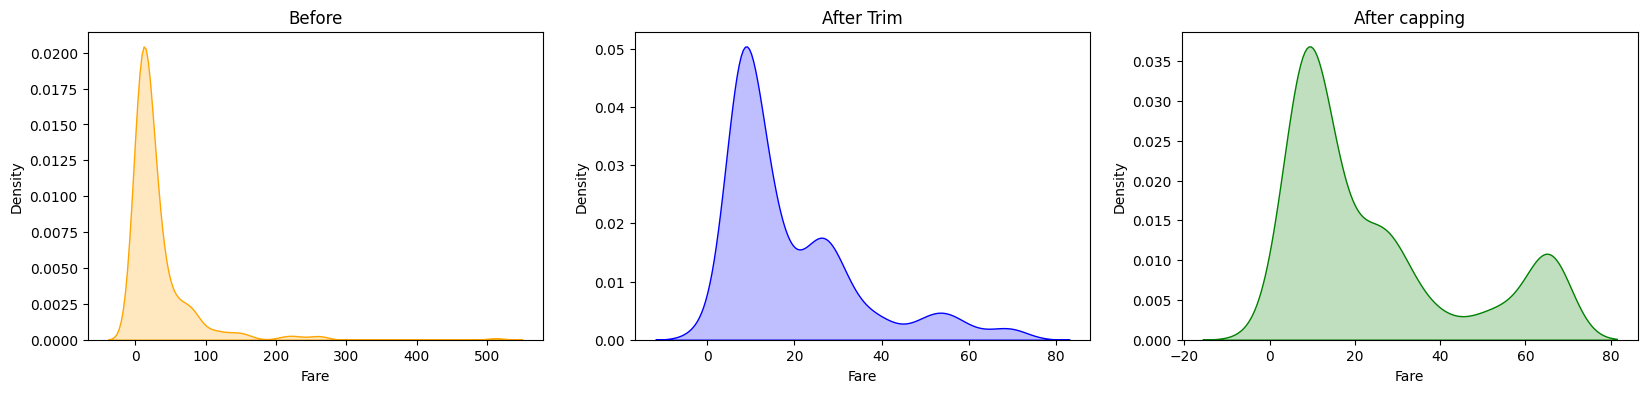

In [289]:
fig , (ax1,ax2,ax3) = plt.subplots(ncols=3,figsize=(20,4))
fig = sns.kdeplot(data['Fare'],fill=True,color='orange',ax=ax1)
ax1.set_title('Before')
fig = sns.kdeplot(new_data['Fare'],fill=True,color='blue',ax=ax2)
ax2.set_title('After Trim')
fig = sns.kdeplot(new_df_cap['Fare'],fill=True,color='green',ax=ax3)
ax3.set_title('After capping')

## **Percentile Method**

In [290]:
df = pd.read_csv(r"C:\Users\LENOVO\Downloads\archive (1)\weight-height.csv")

In [291]:
df.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [292]:
df.shape

(10000, 3)

In [293]:
df['Height'].describe()

count    10000.000000
mean        66.367560
std          3.847528
min         54.263133
25%         63.505620
50%         66.318070
75%         69.174262
max         78.998742
Name: Height, dtype: float64

<Axes: xlabel='Height', ylabel='Count'>

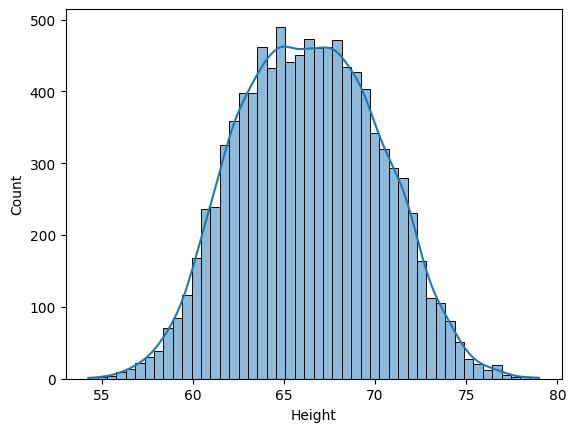

In [294]:
sns.histplot(df['Height'],kde=True)

<Axes: xlabel='Height'>

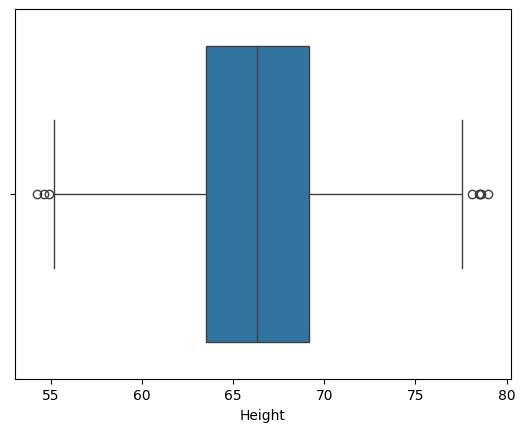

In [295]:
sns.boxplot(x = df['Height'])

In [296]:
upper = df['Height'].quantile(0.99)
lower = df['Height'].quantile(0.01)
# both should be symmetric.

In [297]:
print('Upper: ',upper)
print('Lower: ',lower)

Upper:  74.7857900583366
Lower:  58.13441158671655


## *Outliers*

In [298]:
df[df['Height']>upper]

,Gender,Height,Weight
23,Male,75.205974,228.761781
190,Male,76.709835,235.035419
197,Male,75.944460,231.924749
202,Male,75.140821,224.124271
215,Male,74.795375,232.635403
...,...,...,...
4565,Male,75.690384,223.587548
4569,Male,77.547186,242.041173
4701,Male,76.732446,241.686601
4721,Male,75.330847,240.440816


In [299]:
df[df['Height'] < lower]

,Gender,Height,Weight
5026,Female,56.547975,84.872124
5074,Female,56.159458,90.815256
5122,Female,57.103869,93.506316
5123,Female,56.445685,96.640245
5162,Female,57.961936,112.226984
...,...,...,...
9761,Female,56.975279,90.341784
9825,Female,55.979198,85.417534
9895,Female,57.740192,93.652957
9904,Female,57.028857,101.202551


## **Trim**

In [300]:
new_df_trim = df[(df['Height']<upper) & (df['Height'] > lower)]

In [301]:
new_df_trim.shape

(9800, 3)

## **capping/Winsorization**

In [302]:
new_df_cap = df.copy()
new_df_cap['Height'] = np.where(df['Height'] > upper , upper
                      ,np.where(df['Height']<lower,lower,df['Height']))

In [303]:
new_df_cap['Height'].describe()

count    10000.000000
mean        66.366281
std          3.795717
min         58.134412
25%         63.505620
50%         66.318070
75%         69.174262
max         74.785790
Name: Height, dtype: float64

Text(0.5, 1.0, 'After capping')

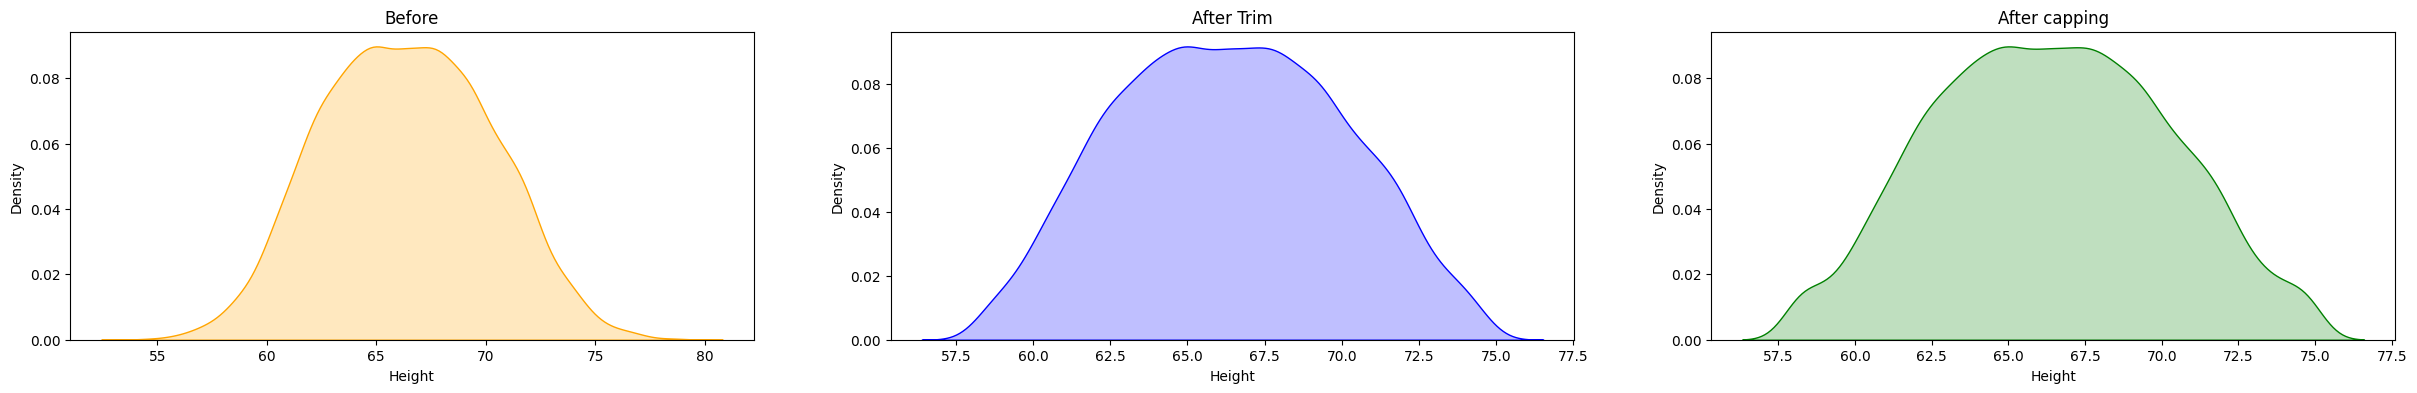

In [310]:
fig , (ax1,ax2,ax3) = plt.subplots(ncols=3,figsize=(30,4))
fig = sns.kdeplot(df['Height'],fill=True,color='orange',ax=ax1)
ax1.set_title('Before')
fig = sns.kdeplot(new_df_trim['Height'],fill=True,color='blue',ax=ax2)
ax2.set_title('After Trim')
fig = sns.kdeplot(new_df_cap['Height'],fill=True,color='green',ax=ax3)
ax3.set_title('After capping')

Text(0.5, 1.0, 'After capping')

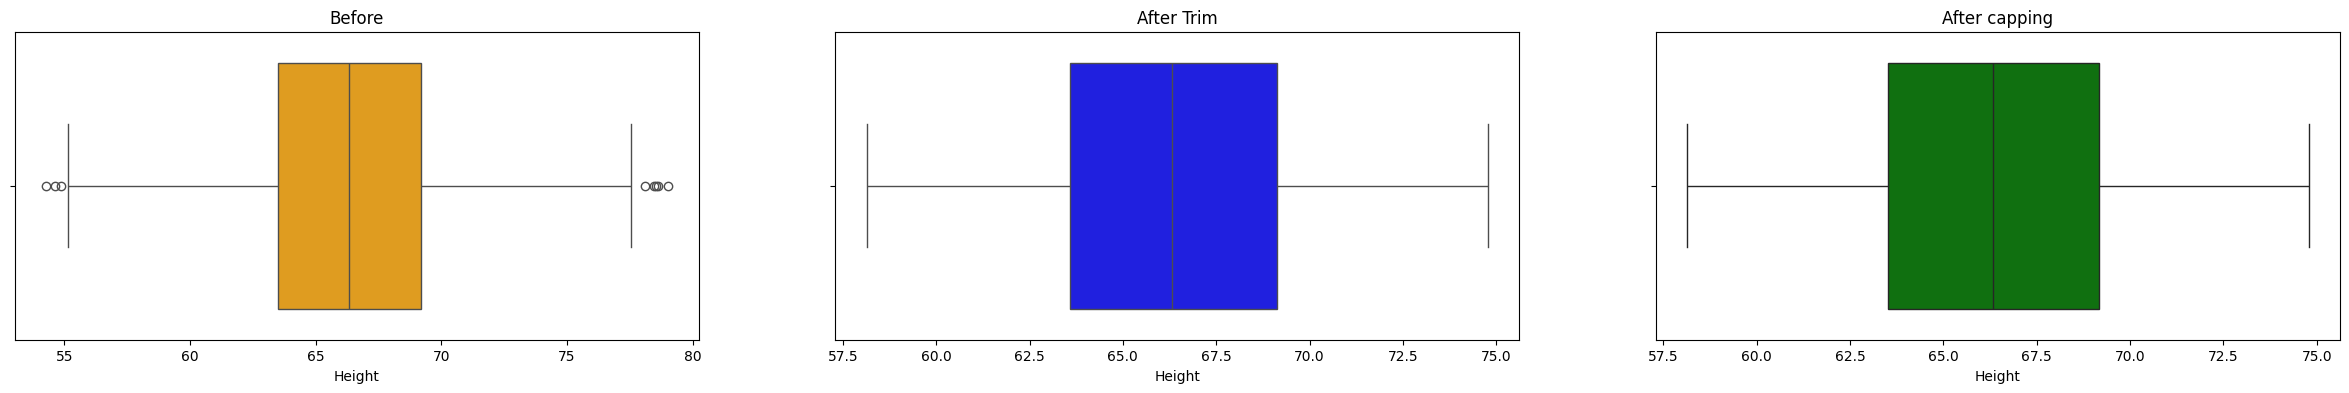

In [309]:
fig , (ax1,ax2,ax3) = plt.subplots(ncols=3,figsize=(30,4))
fig = sns.boxplot(x=df['Height'],color='orange',ax=ax1)
ax1.set_title('Before')
fig = sns.boxplot(x=new_df_trim['Height'],color='blue',ax=ax2)
ax2.set_title('After Trim')
fig = sns.boxplot(x=new_df_cap['Height'],color='green',ax=ax3)
ax3.set_title('After capping')